# Tutorial 3 · Tissue regeneration after colitis
Mouse colon MERFISH (Cadinu et al., 2024): healthy (3 mice) and DSS day 3 (4), day 9 (6) and day 21 (2), one section per mouse.
Fibroblasts turn into inflammation-associated fibroblasts (IAF) during injury. Settings as in the paper (Fig. 4): received signals
from CytoSignal (pre-computed, `obsm['cytosignal']`), every mouse matched to every mouse of the next time point, driver test per
mouse adjusted for tissue neighbourhood and combined across mice, 10% expression filter and sign check.

In [1]:
import glob, anndata as ad, numpy as np, pandas as pd, matplotlib.pyplot as plt
import nichefate as nf
days = ["Healthy", "DSS3", "DSS9", "DSS21"]
S = {d: [ad.read_h5ad(f) for f in sorted(glob.glob(f"../tutorial_data/colitis/{d}_*.h5ad"))] for d in days}
allS = sorted([x for d in days for x in S[d]], key=lambda x: x.n_obs)
LAYER = {"MU": "mucosa", "SM": "submucosa", "ME": "muscularis"}
for x in allS:
    nb = x.obs.neighbourhood.astype(str); x.obs["layer"] = nb.str[:2].map(LAYER).where(~nb.str.startswith("MES"))
pd.DataFrame({d: [len(S[d]), sum(x.n_obs for x in S[d]), sum((x.obs.cell_type == "Fibroblast").sum() for x in S[d])] for d in days}, index=["mice", "cells", "fibroblasts"])

,Healthy,DSS3,DSS9,DSS21
mice,3,4,6,2
cells,78206,103069,194314,86008
fibroblasts,12453,19138,52000,18427


## 1 · Niche and matching

In [2]:
nf.compute_niche(allS, signals=[pd.DataFrame(x.obsm["cytosignal"].astype(float), index=x.obs_names, columns=x.uns["cytosignal_names"]) for x in allS], target_sum=100)
fib = lambda x: (x.obs.cell_type == "Fibroblast").values
res = {(a.uns["mouse"], b.uns["mouse"]): nf.match(a, b, groupby="state", cells1=fib(a), cells2=fib(b), pca_sections=allS, pca_cells=[fib(x) for x in allS], scale_signals=False)
       for d1, d2 in zip(days[:-1], days[1:]) for a in S[d1] for b in S[d2]}
def fate(x):
    rs = [r for (m1, _), r in res.items() if m1 == x.uns["mouse"]]
    p = sum(nf.fate(r, "IAF", among=["IAF", "Fibro"]) for r in rs) / len(rs); x.obs["P_IAF"] = p.reindex(x.obs_names); return rs[0], p
F = {x.uns["mouse"]: fate(x) for d in days[:-1] for x in S[d]}
pd.DataFrame({f"{d1} → {d2}": [np.mean([x.obs.P_IAF[x.obs.state.str.startswith(g)].mean() for x in S[d1]]) for g in ("Fibro", "IAF")]
              for d1, d2 in zip(days[:-1], days[1:])}, index=["fibroblast → IAF", "IAF stays IAF"]).round(2)

943 shared genes, 965 ligand-receptor pairs, 138 signals (pathway)


C:\Users\au827475\Dropbox\Niche-FATE\nichefate\_gnn.py:14: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\Context.cpp:855.)
  At = torch.sparse_coo_tensor(np.vstack([A.row, A.col]), A.data.astype(np.float32), A.shape, device=device).coalesce()


niche computed for 15 sections: [18419, 21035, 21962, 24617, 26249, 27544, 27785, 28603, 31303, 31469, 32002, 35172, 39569, 46439, 49429] cells


,Healthy → DSS3,DSS3 → DSS9,DSS9 → DSS21
fibroblast → IAF,0.11,0.4,0.04
IAF stays IAF,0.74,0.9,0.56


## 2 · Where fibroblasts become IAFs

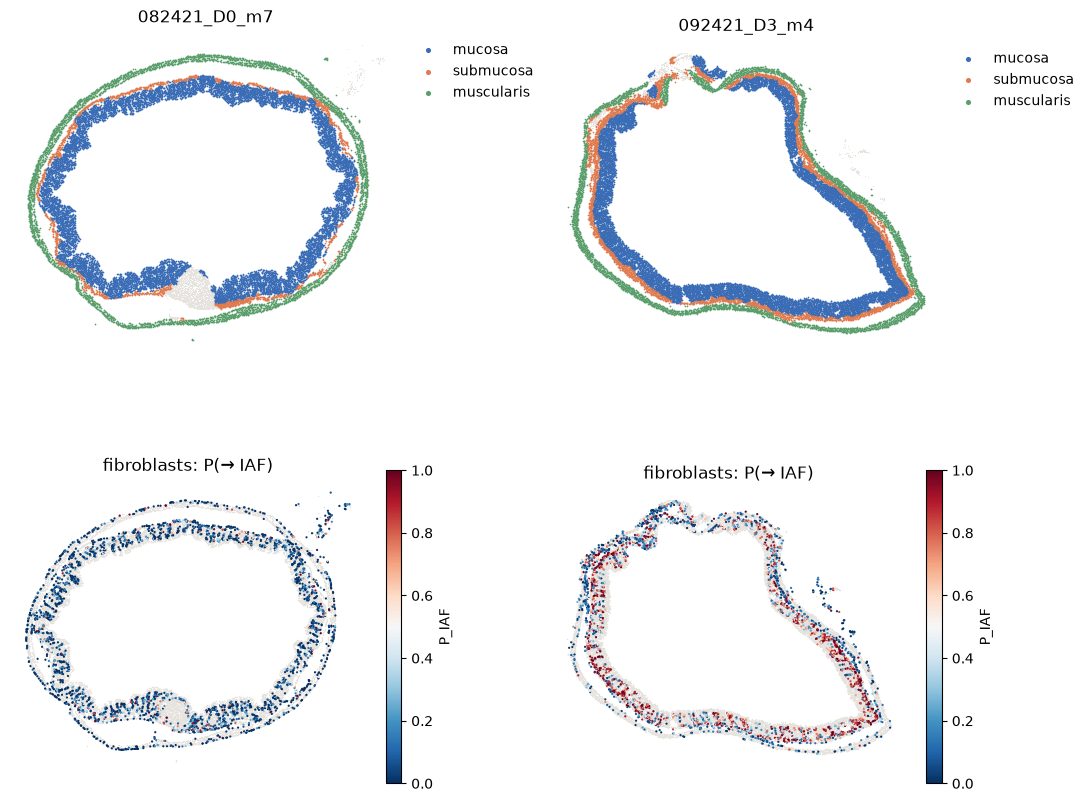

In [3]:
ex = [next(x for x in S["Healthy"] if x.uns["mouse"].endswith("m7")), next(x for x in S["DSS3"] if x.uns["mouse"].endswith("m4"))]
fig, ax = plt.subplots(2, 2, figsize=(11, 9))
for k, x in enumerate(ex):
    nf.pl.groups_map(x, "layer", ax=ax[0, k], s=1.5, order=list(LAYER.values())); ax[0, k].set_title(x.uns["mouse"])
    nf.pl.fate_map(x, "P_IAF", ax=ax[1, k], s=2.5, title="fibroblasts: P(→ IAF)")
plt.tight_layout(); plt.show()

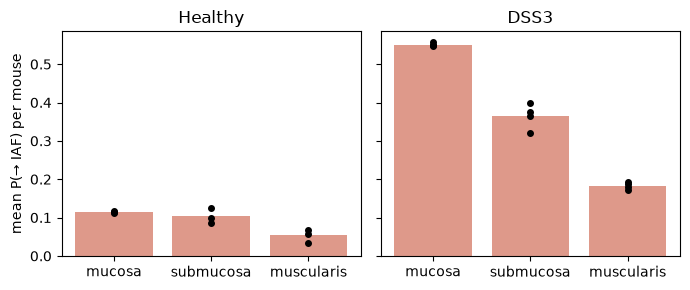

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(7, 3), sharey=True)
for a, d in zip(ax, ["Healthy", "DSS3"]):
    M = pd.DataFrame({x.uns["mouse"]: x.obs[x.obs.state.str.startswith("Fibro")].groupby("layer").P_IAF.mean() for x in S[d]}).reindex(LAYER.values())
    a.bar(range(3), M.mean(1), color="#c8553d", alpha=0.6); [a.plot(range(3), M[c], "o", c="k", ms=4) for c in M]
    a.set_xticks(range(3), M.index); a.set_title(d)
ax[0].set_ylabel("mean P(→ IAF) per mouse"); plt.tight_layout(); plt.show()

## 3 · Signals that induce IAFs (day 3 fibroblasts, 4 mice)

In [5]:
d3 = [F[x.uns["mouse"]] for x in S["DSS3"]]
d = nf.drivers([r for r, _ in d3], [p for _, p in d3], cells=["Fibro"], composition_key="major", covariate_keys=["neighbourhood"],
               celltype_key="cell_type", min_detect=0.10)
print(d.attrs["n_cells"], "cells,", len(d), "signals tested")
d[(d.q < 0.05) & d.stable].round(4)

14252 cells, 47 signals tested


,signal,r,z,p,q,z_1,z_2,z_3,z_4,stable,detect
0,IL16,0.0387,4.3432,0.0000,0.0002,2.0222,2.8775,1.5615,2.2252,True,0.1996
1,CXCL,0.0366,4.1536,0.0000,0.0003,0.5974,2.1146,3.3738,2.2214,True,0.1975
2,ICAM,0.0369,4.1212,0.0000,0.0003,0.6788,2.8402,3.1844,1.5391,True,0.1279
3,SELPLG,0.0332,3.6524,0.0003,0.0016,0.2760,2.4099,3.1418,1.4772,True,0.1531
6,CXCL14,0.0230,2.7058,0.0068,0.0178,0.9465,2.1140,1.4974,0.8539,True,0.1422
7,VEGF,0.0227,2.6470,0.0081,0.0201,2.1179,0.7054,0.2362,2.2345,True,0.2131
8,CX3C,0.0234,2.6053,0.0092,0.0216,1.0085,0.5866,1.8095,1.8060,True,0.2115
9,CDH5,0.0228,2.5505,0.0108,0.0241,0.6584,2.0613,1.2397,1.1414,True,0.3227
42,FGF,-0.0318,-3.6029,0.0003,0.0016,-2.6597,-1.4001,-0.1424,-3.0036,True,0.1213


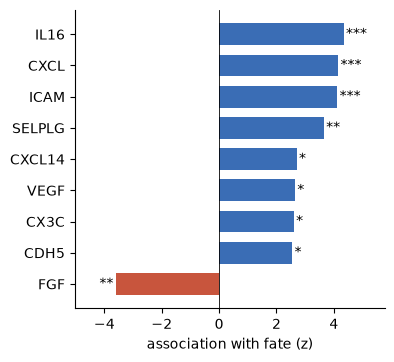

In [6]:
nf.pl.drivers(d, top=12); plt.show()

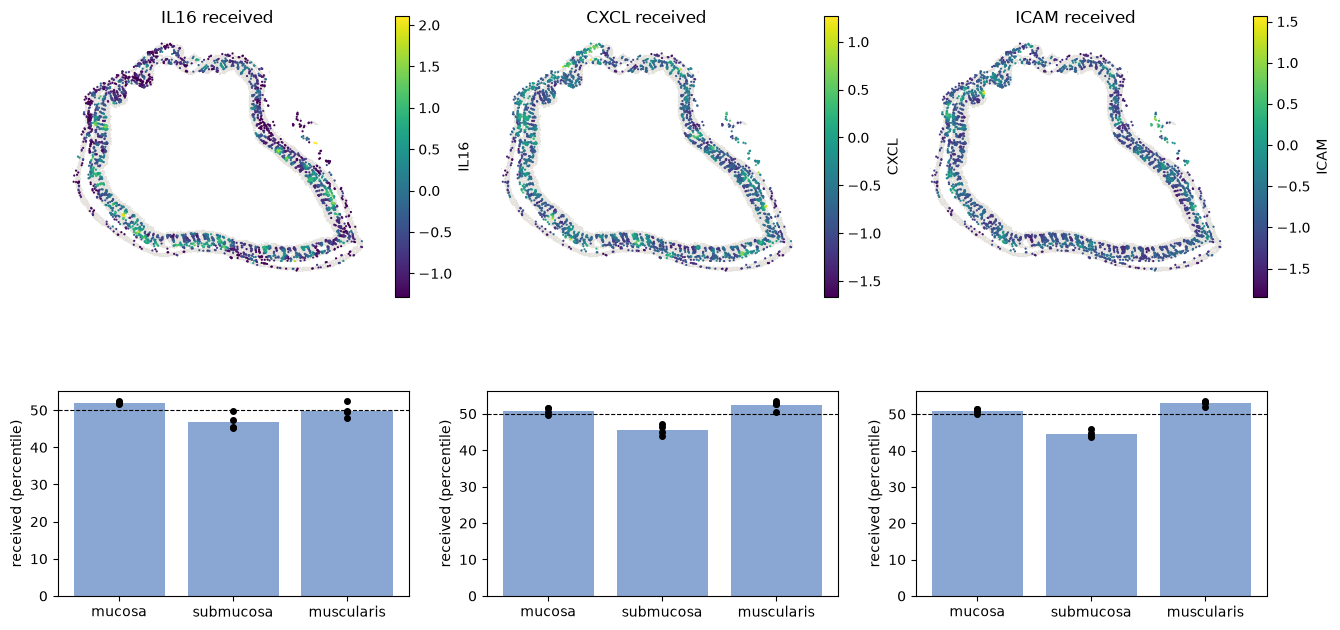

In [7]:
top = d[(d.q < 0.05) & d.stable & (d.z > 0)].signal.head(3).tolist()
fig, ax = plt.subplots(2, len(top), figsize=(4.5 * len(top), 8), gridspec_kw=dict(height_ratios=[3, 1]))
for k, s in enumerate(top):
    x = ex[1]; f = fib(x) & x.obs.state.str.startswith("Fibro").values
    nf.pl.signal_map(x, s, ax=ax[0, k], cells=f, s=2.5)
    M = pd.DataFrame({y.uns["mouse"]: pd.Series(y.obsm["nf_signal"][:, list(y.uns["nf_signal_names"]).index(s)]).rank(pct=True).mul(100)
                      .groupby(y.obs.layer.values).mean() for y in S["DSS3"]}).reindex(LAYER.values())
    ax[1, k].bar(range(3), M.mean(1), color="#3a6db5", alpha=0.6); [ax[1, k].plot(range(3), M[c], "o", c="k", ms=4) for c in M]
    ax[1, k].set_xticks(range(3), M.index); ax[1, k].axhline(50, ls="--", c="k", lw=0.8); ax[1, k].set_ylabel("received (percentile)")
plt.tight_layout(); plt.show()